<a href="https://colab.research.google.com/github/basedalgerianrin/ml-campus_data_project-colab/blob/main/CampusDatasetProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Environment Setup & Data Loading
In this section, we import pandas and configure the environment to handle dataframes and connect with Google Drive to access our dataset.

In [19]:
import pandas as pd

# Configure pandas to display dataframes as interactive or readable tables
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
df = pd.read_csv(
    '/content/drive/MyDrive/MLwithPython/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows=4
)

## 2. Initial Data Inspection and Column Trimming
We set up interactive tables in Colab, display the first 20 rows of the imported dataset, and drop columns beyond the relevant survey observations (such as those after `other_notes`).

In [22]:
import google.colab.data_table

# Configure the interactive table settings before loading the extension
google.colab.data_table.max_columns = 40
google.colab.data_table.enable_dataframe_formatter()
col_index = df.columns.get_loc('other_notes')
columns_to_drop = df.columns[col_index + 1:]
df.drop(columns=columns_to_drop, inplace=True)

# Display the dataframe as an interactive table
df.head(20)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2.0,4.0,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2.0,2.0,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,NaN
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7.0,0.0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,NaN
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3.0,1.0,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,NaN
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6.0,2.0,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,NaN


df.info()

used df.info to get a summarized breakdown of the data and i can pinpoint problems in the df.head table layout

## 3. Data Profile & Structure Assessment
We use `df.info()` to understand the data types, non-null value counts, and overall memory usage of our subsetted dataset.

In [23]:
# Drop all columns after 'other_notes' (which is at column index 22)
col_index = df.columns.get_loc('other_notes')
columns_to_drop = df.columns[col_index + 1:]
df.drop(columns=columns_to_drop, inplace=True)

# Confirm the remaining columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   135 non-null    object 
 2   location                               135 non-null    object 
 3   weather                                135 non-null    object 
 4   temperature_c                          135 non-null    object 
 5   sound level                            135 non-null    object 
 6   foot_traffic                           135 non-null    object 
 7   primary_sound_type_urban               135 non-null    object 
 8   other_sound_type_urban                 132 non-null    object 
 9   primary_sound_type_nature              135 non-null    object 
 10  other_sound_type_nature                133 non-null    object 
 11  insect

## 4. Handling Missing and Duplicate Values
Here we explore dropping missing values (NaN) to create a clean subset (`new_df`) and check the dataset for duplicate rows to ensure data integrity.

In [24]:
new_df = df.dropna()
print(new_df.head(20))

    recorder_id       date                       location        weather temperature_c sound level foot_traffic primary_sound_type_urban other_sound_type_urban primary_sound_type_nature other_sound_type_nature  insects_count  birds_count trees_presence native_or_wild_plant_presence ornnamental_or_planted_plant_presence moss_or_lichen_presence         wellbeing_rating     ease_rating stress_rating nature_connection_experience_rating     most_notable_nature_element                                other_notes
5       R26_002  9/22/2026               L01 MainEntrance          Sunny            17    Moderate          Low                  Traffic           Human voices               Other birds                 Insects            2.0          4.0           Many                         Some                                  Some                     Many       Positive wellbeing            Easy   Mostly calm             A little more connected                           trees                      

In [25]:
print(df.duplicated().head(20))

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
dtype: bool


## Week 6 15/10/2026


| Item | Details |
|-------|---------|
| Issue or Challenge Identified |Knowing what to do|
| Decision Taken |Research and experimentation |
| Justification |To understand what needs to be done |
| Evidence Supporting the Decision | No Evidence |
| Reflection | Next Week should have more clarity on what the next steps are |




In [26]:
# Define the Mapping dictionary

sound_mapping = {
    'Quiet' : 0,
    'Moderate' : 1,
    'Loud' : 2
}

df['sound_level_encoded'] = df['sound level'].map(sound_mapping)

#Verify mapping and check data types
print(df[['sound level', 'sound_level_encoded']]
      .drop_duplicates()
      .reset_index(drop=True)
      )

  sound level  sound_level_encoded
0       Quiet                  0.0
1    Moderate                  1.0
2        Loud                  2.0
3         NaN                  NaN


## 5. Cleaning and Standardizing Date Values

Date data often comes with formatting issues, inconsistencies, or mixed data types. Date data cleaning generally involves the following steps:

1. **Standardization**: Converting various text formats (such as `MM/DD/YYYY`, `DD-MM-YYYY`, or textual representations) into a uniform, standard date format (usually ISO 8601: `YYYY-MM-DD`).
2. **Type Casting**: Transforming the data from generic strings (`object` type in pandas) into a specialized datetime data type (`datetime64`). This enables chronological sorting, date filtering, and extraction of components like day of the week, month, or year.
3. **Handling Anomalies**: Identifying and treating missing values, out-of-range dates, or unparseable text strings using strategies like coercion (converting errors to `NaT` or Not-a-Time).

In [27]:
# Clean and convert the 'date' column to a standard datetime format
df['cleaned_date'] = pd.to_datetime(df['date'], errors='coerce')

# Display the unique date values before and after cleaning to verify
unique_dates = df[['date', 'cleaned_date']].drop_duplicates().dropna().reset_index(drop=True)
display(unique_dates.head(10))

,date,cleaned_date
0,9/22/2026,2026-09-22
1,9/23/2026,2026-09-23
2,9/24/2026,2026-09-24
3,9/25/2026,2026-09-25
4,9/26/2026,2026-09-26
5,9/27/2026,2026-09-27
6,9/28/2026,2026-09-28
7,10/7/2026,2026-10-07


In [28]:
# Clean and convert 'temperature_c' to a numeric type, stripping any non-numeric characters (like 'C')
df['cleaned_temp'] = pd.to_numeric(df['temperature_c'].astype(str).str.replace('C', '', case=False), errors='coerce')

# Display the unique temperature values to verify the cleaning
unique_temps = df[['temperature_c', 'cleaned_temp']].drop_duplicates().dropna().reset_index(drop=True)
display(unique_temps.head(10))

,temperature_c,cleaned_temp
0,16,16.0
1,17,17.0
2,19,19.0
3,18,18.0
4,15,15.0
5,13,13.0
6,16.5,16.5
7,14,14.0
8,17C,17.0
9,16C,16.0


In [29]:
foot_mapping = {
    'Low' : 0,
    'Moderate' : 1,
    'High' : 2
}

# Standardize column values to Title Case to handle mixed capitalization (like 'low' vs 'Low')
df['foot_traffic_encoded'] = df['foot_traffic'].str.replace('c','C', case = True).map(foot_mapping)

# Verify mapping
print(df[['foot_traffic', 'foot_traffic_encoded']]
      .drop_duplicates()
      .dropna()
      .reset_index(drop=True)
      )

  foot_traffic  foot_traffic_encoded
0          Low                   0.0
1     Moderate                   1.0
2         High                   2.0


## 6. One-Hot Encoding Categorical Sound Types & Weather Data
We can apply One-Hot Encoding to convert categorical text fields (like weather conditions and specific urban/nature sound types) into discrete numerical columns.

In [30]:
# 1. Standardize text capitalization in the weather column first to merge 'Sunny' and 'sunny'
df['weather'] = df['weather'].str.strip().str.title()

# Columns to encode
categorical_cols = ['weather', 'primary_sound_type_urban', 'primary_sound_type_nature', ]

# 2. Perform one-hot encoding on the specified columns
encoded_df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)

# Display the newly generated columns
new_encoded_columns = [col for col in encoded_df.columns if any(cat in col for cat in categorical_cols)]
display(encoded_df[new_encoded_columns].head(10))

,weather_Partly Cloudy,weather_Sunny,weather_Windy,primary_sound_type_urban_Human voices,primary_sound_type_urban_Other,primary_sound_type_urban_Service machinery,primary_sound_type_urban_Traffic,primary_sound_type_nature_Other,primary_sound_type_nature_Other birds,primary_sound_type_nature_Seagulls,primary_sound_type_nature_Trees,primary_sound_type_nature_Wind
0,True,False,False,True,False,False,False,False,False,False,False,True
1,False,True,False,False,False,False,True,False,False,False,False,True
2,True,False,False,False,False,False,False,False,False,False,False,True
3,True,False,False,True,False,False,False,False,False,False,False,True
4,False,True,False,False,False,False,True,False,False,False,False,True
5,False,True,False,False,False,False,True,False,True,False,False,False
6,False,False,True,False,False,False,True,False,False,False,False,True
7,False,True,False,False,False,False,True,False,False,False,False,True
8,False,False,False,False,False,False,True,False,False,False,False,True
9,False,True,False,False,False,True,False,False,True,False,False,False


In [31]:
# Convert boolean True/False values in the encoded DataFrame columns to numerical 1/0
encoded_df[new_encoded_columns] = encoded_df[new_encoded_columns].astype(int)

# Display the updated columns to verify numerical output
display(encoded_df[new_encoded_columns].head(10))

,weather_Partly Cloudy,weather_Sunny,weather_Windy,primary_sound_type_urban_Human voices,primary_sound_type_urban_Other,primary_sound_type_urban_Service machinery,primary_sound_type_urban_Traffic,primary_sound_type_nature_Other,primary_sound_type_nature_Other birds,primary_sound_type_nature_Seagulls,primary_sound_type_nature_Trees,primary_sound_type_nature_Wind
0,1,0,0,1,0,0,0,0,0,0,0,1
1,0,1,0,0,0,0,1,0,0,0,0,1
2,1,0,0,0,0,0,0,0,0,0,0,1
3,1,0,0,1,0,0,0,0,0,0,0,1
4,0,1,0,0,0,0,1,0,0,0,0,1
5,0,1,0,0,0,0,1,0,1,0,0,0
6,0,0,1,0,0,0,1,0,0,0,0,1
7,0,1,0,0,0,0,1,0,0,0,0,1
8,0,0,0,0,0,0,1,0,0,0,0,1
9,0,1,0,0,0,1,0,0,1,0,0,0


## 6.5. Feature Scaling
We apply feature scaling using MinMaxScaler and StandardScaler from `sklearn.preprocessing` to normalize our continuous numerical variables (`cleaned_temp`, `birds_count`, and `insects_count`).

In [34]:
scaler = StandardScaler()
scaled_feature = scaler.fit_transform(df[['cleaned_temp', 'birds_count', 'insects_count']])
print(scaled_feature)

[[-4.83561966e-01 -3.57106127e-01 -5.37245979e-01]
 [-4.83561966e-01  2.66497110e-03 -5.37245979e-01]
 [-4.83561966e-01  6.47854474e+00  1.42828809e+00]
 ...
 [            nan             nan             nan]
 [            nan             nan             nan]
 [            nan             nan             nan]]


In [35]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Define continuous numerical columns to scale
num_cols = ['cleaned_temp', 'birds_count', 'insects_count']

# Create a copy of the dataframe to store scaled features
scaled_df = encoded_df.copy()

# 1. Min-Max Scaling (Scale features between 0 and 1)
min_max_scaler = MinMaxScaler()
scaled_df[[f'{col}_minmax' for col in num_cols]] = min_max_scaler.fit_transform(encoded_df[num_cols])

# 2. Standard Scaling (Scale features to mean=0, std=1)
std_scaler = StandardScaler()
scaled_df[[f'{col}_standard' for col in num_cols]] = std_scaler.fit_transform(encoded_df[num_cols])

# Display the original and scaled values side-by-side to verify
comparison_cols = []
for col in num_cols:
    comparison_cols.extend([col, f'{col}_minmax', f'{col}_standard'])

display(scaled_df[comparison_cols].head(10))

,cleaned_temp,cleaned_temp_minmax,cleaned_temp_standard,birds_count,birds_count_minmax,birds_count_standard,insects_count,insects_count_minmax,insects_count_standard
0,16.0,0.666667,-0.483562,1.0,0.05,-0.357106,0.0,0.000000,-0.537246
1,16.0,0.666667,-0.483562,2.0,0.10,0.002665,0.0,0.000000,-0.537246
2,16.0,0.666667,-0.483562,20.0,1.00,6.478545,10.0,0.322581,1.428288
3,16.0,0.666667,-0.483562,2.0,0.10,0.002665,0.0,0.000000,-0.537246
4,16.0,0.666667,-0.483562,0.0,0.00,-0.716877,0.0,0.000000,-0.537246
5,17.0,0.777778,0.262505,4.0,0.20,0.722207,2.0,0.064516,-0.144139
6,17.0,0.777778,0.262505,2.0,0.10,0.002665,2.0,0.064516,-0.144139
7,19.0,1.000000,1.754639,0.0,0.00,-0.716877,7.0,0.225806,0.838628
8,16.0,0.666667,-0.483562,1.0,0.05,-0.357106,3.0,0.096774,0.052414
9,18.0,0.888889,1.008572,2.0,0.10,0.002665,6.0,0.193548,0.642074


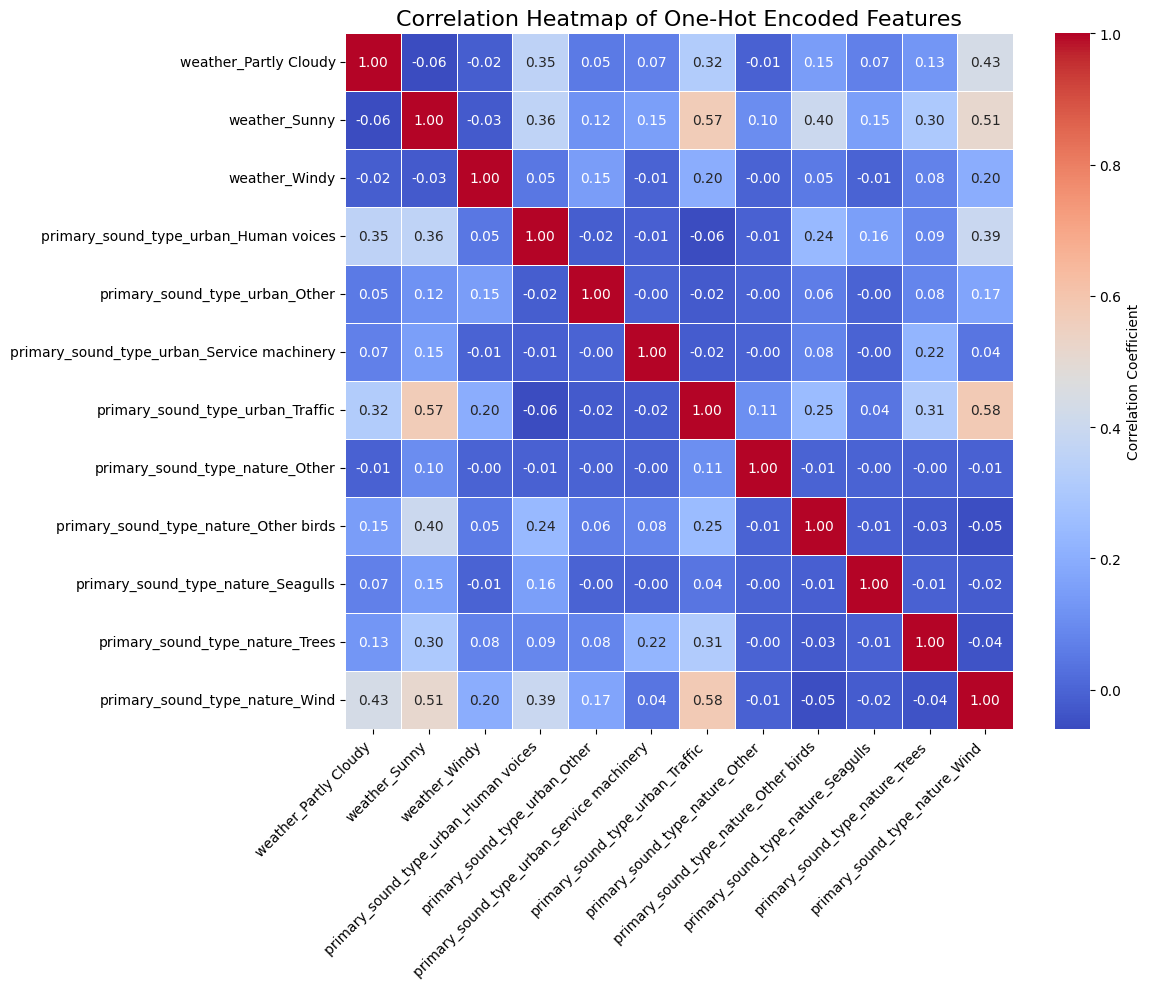

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix for the new one-hot encoded columns
corr_matrix = encoded_df[new_encoded_columns].corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title('Correlation Heatmap of One-Hot Encoded Features', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Weekly Progress Logs

This section consolidates all weekly progress templates, challenging reflections, and decision-making logs throughout the duration of this analysis.

### Week 6: 15/10/2026

| Item | Details |
| :--- | :--- |
| **Issue or Challenge Identified** | Knowing what to do |
| **Decision Taken** | Research and experimentation |
| **Justification** | To understand what needs to be done |
| **Evidence Supporting the Decision** | No Evidence |
| **Reflection** | Next Week should have more clarity on what the next steps are |

### Week 7: 05/11/2026

| Item | Details |
| :--- | :--- |
| **Issue or Challenge Identified** | Knowing what to do |
| **Decision Taken** | Research and experimentation |
| **Justification** | To understand what needs to be done |
| **Evidence Supporting the Decision** | No Evidence |
| **Reflection** | Next Week should have more clarity on what the next steps are |